<a href="https://colab.research.google.com/github/sihamaness22-design/Dry-Bean-MLflow-Experiments/blob/main/Dry_Bean_MLflow_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install -q mlflow scikit-learn pandas openpyxl matplotlib

from google.colab import files
import pandas as pd

# اختاري ملف Dry_Bean_Dataset.xlsx من جهازك
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name)

print(f"تم تحميل الملف بنجاح: {file_name} | عدد الصفوف والأعمدة: {df.shape}")
df.head()

Saving Dry_Bean_Dataset.xlsx to Dry_Bean_Dataset.xlsx
تم تحميل الملف بنجاح: Dry_Bean_Dataset.xlsx | عدد الصفوف والأعمدة: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
import mlflow
import mlflow.sklearn
import mlflow.data
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

# استيراد 5 خوارزميات مختلفة للمقارنة
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# تجهيز البيانات
X = df.drop(columns=['Class'])
y = df['Class']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# تعريف التجارب الخمس
experiments_config = [
    {
        "run_name": "Exp1_RandomForest_100",
        "model_type": "RandomForest",
        "params": {"n_estimators": 100, "max_depth": 12, "random_state": 42},
        "model": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
    },
    {
        "run_name": "Exp2_ExtraTrees_150",
        "model_type": "ExtraTrees",
        "params": {"n_estimators": 150, "max_depth": 15, "random_state": 42},
        "model": ExtraTreesClassifier(n_estimators=150, max_depth=15, random_state=42)
    },
    {
        "run_name": "Exp3_SVM_RBF",
        "model_type": "SVM",
        "params": {"C": 10.0, "kernel": "rbf", "random_state": 42},
        "model": SVC(C=10.0, kernel="rbf", random_state=42)
    },
    {
        "run_name": "Exp4_GradientBoosting",
        "model_type": "GradientBoosting",
        "params": {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 5, "random_state": 42},
        "model": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
    },
    {
        "run_name": "Exp5_NeuralNetwork_MLP",
        "model_type": "MLPClassifier",
        "params": {"hidden_layer_sizes": "(128, 64)", "max_iter": 300, "random_state": 42},
        "model": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=300, random_state=42)
    }
]

# إنشاء التجربة في MLflow
mlflow.set_experiment("Dry_Bean_5_Models_Comparison")
dataset = mlflow.data.from_pandas(df, source=file_name, name="Dry_Bean_Dataset")

comparison_results = []

for exp in experiments_config:
    with mlflow.start_run(run_name=exp["run_name"]):
        mlflow.log_input(dataset, context="training")
        mlflow.log_param("model_type", exp["model_type"])
        for k, v in exp["params"].items():
            mlflow.log_param(k, v)

        # التدريب والتقييم
        clf = exp["model"]
        clf.fit(X_train_scaled, y_train)
        y_pred = clf.predict(X_test_scaled)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average="weighted")

        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("f1_weighted", f1)

        # حفظ مصفوفة الارتباك
        fig, ax = plt.subplots(figsize=(7, 5))
        ConfusionMatrixDisplay.from_predictions(
            y_test, y_pred, display_labels=le.classes_, ax=ax, cmap="Blues", xticks_rotation=45
        )
        plt.title(f"Confusion Matrix - {exp['run_name']}")
        plt.tight_layout()
        mlflow.log_figure(fig, f"cm_{exp['run_name']}.png")
        plt.close(fig)

        comparison_results.append({
            "Experiment": exp["run_name"],
            "Algorithm": exp["model_type"],
            "Accuracy": round(acc, 4),
            "Weighted_F1": round(f1, 4)
        })
        print(f"اكتملت {exp['run_name']} -> Accuracy: {acc:.4f} | F1: {f1:.4f}")

# عرض جدول المقارنة النهائي وتحديد الأفضل
results_df = pd.DataFrame(comparison_results).sort_values(by="Accuracy", ascending=False)
print("\n=== جدول مقارنة التجارب الخمس ===")
display(results_df)

best_exp = results_df.iloc[0]
print(f"\n🏆 النموذج الأفضل هو: {best_exp['Experiment']} بدقة Accuracy = {best_exp['Accuracy']}")

2026/11/16 19:46:13 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/16 19:46:13 INFO mlflow.store.db.utils: Updating database tables
2026/11/16 19:46:18 INFO mlflow.tracking.fluent: Experiment with name 'Dry_Bean_5_Models_Comparison' does not exist. Creating a new experiment.
/usr/local/lib/python3.13/dist-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(
/usr/local/lib/python3.13/dist-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is 

اكتملت Exp1_RandomForest_100 -> Accuracy: 0.9192 | F1: 0.9192
اكتملت Exp2_ExtraTrees_150 -> Accuracy: 0.9144 | F1: 0.9145
اكتملت Exp3_SVM_RBF -> Accuracy: 0.9243 | F1: 0.9243
اكتملت Exp4_GradientBoosting -> Accuracy: 0.9247 | F1: 0.9246
اكتملت Exp5_NeuralNetwork_MLP -> Accuracy: 0.9288 | F1: 0.9285

=== جدول مقارنة التجارب الخمس ===


,Experiment,Algorithm,Accuracy,Weighted_F1
4,Exp5_NeuralNetwork_MLP,MLPClassifier,0.9288,0.9285
3,Exp4_GradientBoosting,GradientBoosting,0.9247,0.9246
2,Exp3_SVM_RBF,SVM,0.9243,0.9243
0,Exp1_RandomForest_100,RandomForest,0.9192,0.9192
1,Exp2_ExtraTrees_150,ExtraTrees,0.9144,0.9145



🏆 النموذج الأفضل هو: Exp5_NeuralNetwork_MLP بدقة Accuracy = 0.9288


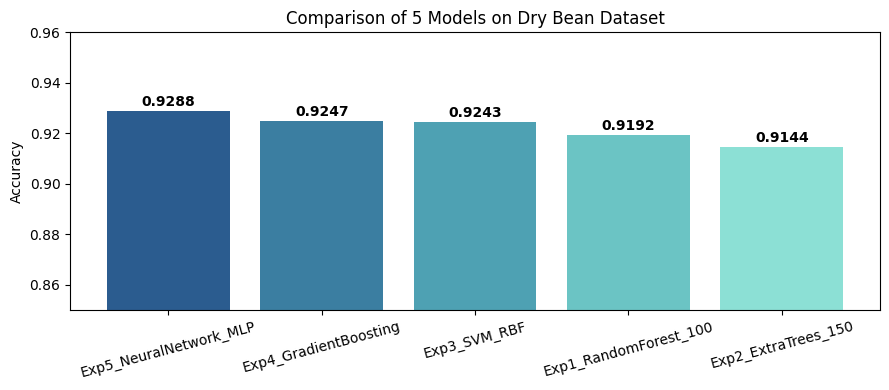

In [5]:
plt.figure(figsize=(9, 4))
bars = plt.bar(results_df["Experiment"], results_df["Accuracy"], color=['#2b5c8f', '#3b7ea1', '#4ea1b3', '#6bc4c4', '#8ce0d5'])
plt.ylim(0.85, 0.96)
plt.ylabel("Accuracy")
plt.title("Comparison of 5 Models on Dry Bean Dataset")
plt.xticks(rotation=15)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.002, f"{yval:.4f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [6]:
import time

!npm install -g localtunnel
!pkill -f "mlflow"
time.sleep(2)

get_ipython().system_raw(
    "mlflow ui --host 0.0.0.0 --port 5000 --allowed-hosts '*' --cors-allowed-origins '*' &"
)
time.sleep(4)

print("كلمة مرور النفق (Tunnel Password):")
!curl ipv4.icanhazip.com

!npx localtunnel --port 5000

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇
added 22 packages in 5s
⠇
⠇3 packages are looking for funding
⠇  run `npm fund` for details
⠇npm notice
npm notice New major version of npm available! 10.8.2 -> 12.2.2
npm notice Changelog: https://github.com/npm/cli/releases/tag/v12.2.2
npm notice To update run: npm install -g npm@12.2.2
npm notice
⠇كلمة مرور النفق (Tunnel Password):
34.139.98.220
⠙⠹⠸⠼⠴⠦⠧⠇your url is: https://beige-berries-win.loca.lt
^C
